# FPSO em 6 graus de liberdade com o Capytaine
### Tutorial passo a passo · PNV3425 – Projeto de Sistemas Oceânicos

Na aula anterior resolvemos o **Exercício 6** (RAO de heave do FPSO de 250 × 40 × 12 m) de três formas: pelo modelo analítico da aula, pelo Capytaine (só heave) e pelo WAMIT. Agora vamos usar o Capytaine para resolver o mesmo casco **nos seis graus de liberdade**, com **a mesma configuração da rodada do WAMIT**, e comparar os RAOs dos dois programas.

**O que você vai aprender**

1. Ler a configuração de uma rodada do WAMIT (frequências, direções, massa, amortecimento externo) e reproduzi-la no Capytaine.
2. Importar uma malha do WAMIT (arquivo `.gdf`) e separar o casco da superfície livre interna.
3. Montar um corpo flutuante com 6 graus de liberdade, com matriz de massa e rigidez hidrostática.
4. Resolver os problemas de radiação e difração e interpretar massa adicional, amortecimento e RAO.
5. Inserir um amortecimento externo no roll e ver o efeito no RAO.
6. Comparar os RAOs do Capytaine e do WAMIT nos seis graus de liberdade.

**Antes de começar**

- Pacotes: `pip install capytaine matplotlib xarray pandas` (testado com Capytaine 3.0).
- Estrutura de pastas esperada (a mesma da Aula 09):

```
Aula 09/
├── Exercicio6_codigos/WAMIT-FPSO/   ← rodada do WAMIT (entradas e saídas)
└── Modelo numérico/
    ├── tutorial_capytaine_6gl.ipynb ← este notebook
    └── wamit_io.py                  ← leitor dos arquivos do WAMIT
```

- Tempo de execução: o cálculo completo (60 frequências × 25 direções × 6 graus de liberdade) leva **cerca de 4 minutos** em 2 núcleos. Com `RAPIDO = True` (célula seguinte) ele cai para 1 a 2 minutos, com um terço das frequências e só três direções. O resultado é salvo em disco e reaproveitado nas próximas execuções.

## 0. Preparação do ambiente

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import capytaine as cpt

import wamit_io as wio            # leitor dos arquivos do WAMIT (mesma pasta)

cpt.set_logging('ERROR')         # 'INFO' mostra mensagens detalhadas do cálculo
print('Capytaine', cpt.__version__)

# ---------------- opções do tutorial
RAPIDO = False                   # True: menos frequências e direções (teste rápido)
REUSAR = True                    # reaproveita o resultado salvo, se existir

PASTA_WAMIT = Path('..') / 'Exercicio6_codigos' / 'WAMIT-FPSO'
ARQ_RESULTADO = Path('capytaine_fpso_6gl.nc')
assert PASTA_WAMIT.exists(), f'Pasta do WAMIT não encontrada: {PASTA_WAMIT.resolve()}'

# graus de liberdade, unidades e cores usadas nos gráficos
DOFS = ['Surge', 'Sway', 'Heave', 'Roll', 'Pitch', 'Yaw']
ROT = {'Roll', 'Pitch', 'Yaw'}
COR = {'Capytaine': '#E8702A', 'WAMIT': '#7A4EAB'}
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})

Capytaine 3.0.0


## 1. A configuração do WAMIT que vamos reproduzir

Uma rodada do WAMIT é definida por poucos arquivos. A tabela mostra onde está cada informação e como ela aparece no Capytaine.

| Informação | Arquivo do WAMIT | No Capytaine |
|---|---|---|
| Malha do casco e da superfície livre interna | `ship_low.gdf` (`IRR = 1` em `config.wam`) | `cpt.load_mesh(...)`, `mesh` + `lid_mesh` |
| Frequências e direções de onda | `poten.pot` (`IPERIN = 2`: ω em rad/s) | coordenadas `omega` e `wave_direction` da matriz de teste |
| Densidade, gravidade, profundidade | `force.frc`, cabeçalho do `.gdf`, `poten.pot` | coordenadas `rho`, `g`, `water_depth` |
| Formulação do problema de contorno | `ISOR = 0` em `config.wam` (formulação de potencial) | `cpt.BEMSolver(method='direct')` |
| Centro de gravidade e de rotação | `ship.frc` (XCG) | `center_of_mass`, `rotation_center` |
| Matriz de massa | `ship.frc` (IMASS = 1) | `body.inertia_matrix` |
| Amortecimento externo | `ship.frc` (IDAMP = 1) | argumento `dissipation` de `cpt.post_pro.rao` |
| Rigidez hidrostática | calculada (`force.hst`) | `body.compute_hydrostatic_stiffness()` |

O módulo `wamit_io.py` lê esses arquivos e converte tudo para unidades SI (kg, N, m, rad).

In [2]:
omegas_wamit, betas_wamit = wio.ler_poten(PASTA_WAMIT)
frc = wio.ler_frc(PASTA_WAMIT)

L, B, T = 250, 40, 12

RHO = frc['rho']          # 1025 kg/m3 (o WAMIT usa 1,025 t/m3)
G = 9.80665 # gravidade do cabeçalho do .gdf
CG = tuple([0.0, 0.0, 0.0])   # centro de gravidade = centro de rotação

print(f'Frequências: {len(omegas_wamit)} valores, de {omegas_wamit.min()} a {omegas_wamit.max()} rad/s')
print(f'Direções   : {len(betas_wamit)} valores, de {betas_wamit.min():.0f}° a {betas_wamit.max():.0f}°')
print(f'ρ = {RHO} kg/m³, g = {G} m/s², CG = {CG} m')

Vol = L * B * T
M = RHO * Vol
Rxx = 0.35 * B
Ryy = 0.25 * L
Rzz = np.sqrt(Rxx**2 + Ryy**2)
print(f'Volume do casco (m³): {Vol:.2f}, Massa (t): {M/1000:.2f}')
print(f'Raio de giro (m): Rxx = {Rxx:.2f}, Ryy = {Ryy:.2f}, Rzz = {Rzz:.2f}')

MM = np.diag([M, M, M, M*Rxx**2, M*Ryy**2, M*Rzz**2])
Bext = np.diag([0, 0, 0, 0, 0, 0])   # amortecimento externo
Kext = np.diag([0, 0, 0, 0, 0, 0])   # rigidez externa

pd.DataFrame({'massa / inércia': np.diag(MM),
             'amortecimento externo': np.diag(Bext),
             'rigidez externa': np.diag(Kext)},
          index=DOFS).style.format('{:.4g}')

Frequências: 60 valores, de 0.01 a 1.55 rad/s
Direções   : 25 valores, de 0° a 360°
ρ = 1025.0 kg/m³, g = 9.80665 m/s², CG = (0.0, 0.0, 0.0) m
Volume do casco (m³): 120000.00, Massa (t): 123000.00
Raio de giro (m): Rxx = 14.00, Ryy = 62.50, Rzz = 64.05


,massa / inércia,amortecimento externo,rigidez externa
Surge,1.23e+08,0,0
Sway,1.23e+08,0,0
Heave,1.23e+08,0,0
Roll,2.411e+10,0,0
Pitch,4.805e+11,0,0
Yaw,5.046e+11,0,0


## 2. Malha: importando o GDF do WAMIT

O arquivo `ship_low.gdf` é a malha de ordem baixa usada pelo WAMIT. Ele tem dois tipos de painel:

- **casco** – a superfície molhada da caixa (fundo, costados e extremidades);
- **superfície livre interna** – painéis em z = 0, dentro da linha d'água, que o WAMIT usa com `IRR = 1`.

No Capytaine, essa superfície interna é a **tampa** (`lid_mesh`) do corpo. Basta separar os painéis com centro em z = 0.

In [3]:
malha_gdf = cpt.load_mesh(PASTA_WAMIT / 'ship_low.gdf', file_format='gdf')
zc = malha_gdf.faces_centers[:, 2]
casco = malha_gdf.extract_faces(np.where(np.abs(zc) > 1e-6)[0], name='casco')
tampa = malha_gdf.extract_faces(np.where(np.abs(zc) <= 1e-6)[0], name='tampa')

print(f'Painéis no arquivo  : {malha_gdf.nb_faces}')
print(f'  casco             : {casco.nb_faces}')
print(f'  superfície interna: {tampa.nb_faces}')
print(f'Volume deslocado    : {casco.disp_volume:.0f} m³   (L·B·T = 120000 m³)')
print(f'Área de linha d’água: {casco.waterplane_area:.0f} m²   (L·B = 10000 m²)')
print(f'Centro de carena    : {np.round(casco.center_of_buoyancy, 3)} m')

Painéis no arquivo  : 3332
  casco             : 2156
  superfície interna: 1176
Volume deslocado    : 120000 m³   (L·B·T = 120000 m³)
Área de linha d’água: 10000 m²   (L·B = 10000 m²)
Centro de carena    : [-0. -0. -6.] m


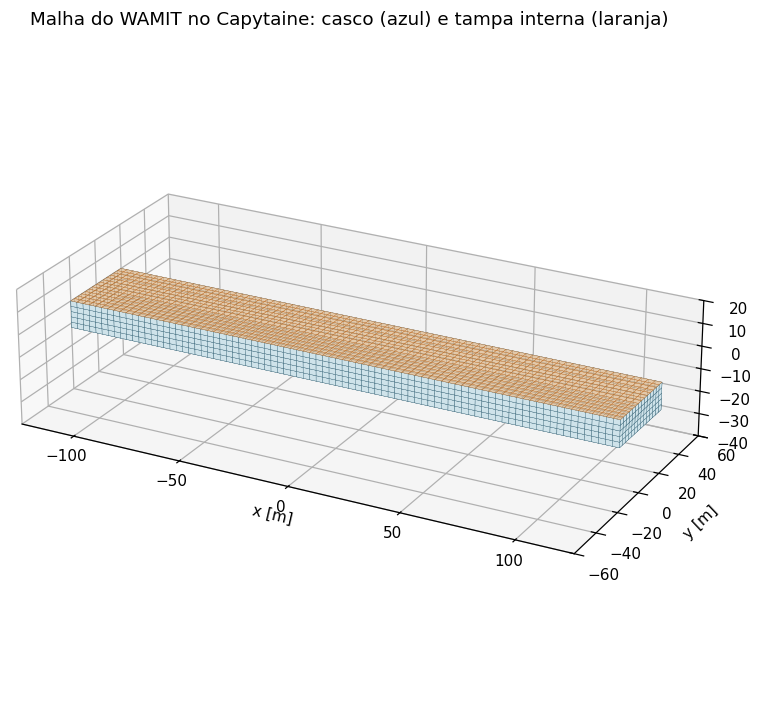

In [22]:
def desenha_malha(ax, malha, face, borda, alpha=1.0):
    ax.add_collection3d(Poly3DCollection(malha.vertices[malha.faces], facecolor=face,
                                         edgecolor=borda, linewidths=0.2, alpha=alpha))

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
desenha_malha(ax, casco, '#CFE3EA', '#1D4E63')
desenha_malha(ax, tampa, '#F2B880', '#B5651D', alpha=0.6)
ax.set_xlim(-125, 125); ax.set_ylim(-60, 60); ax.set_zlim(-40, 20)
ax.set_box_aspect((250, 120, 60)); ax.view_init(elev=24, azim=-62)
ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]'); ax.set_zlabel('z [m]')
ax.set_title('Malha do WAMIT no Capytaine: casco (azul) e tampa interna (laranja)')
plt.show()

**Tamanho dos painéis.** Os painéis têm cerca de 2,5 m. A regra prática é ter pelo menos 6 a 8 painéis por comprimento de onda na maior frequência: com ω = 1,55 rad/s, λ = 2πg/ω² ≈ 26 m, ou seja, cerca de 10 painéis por onda.

## 3. Corpo flutuante com 6 graus de liberdade

Três escolhas definem o corpo:

1. **Graus de liberdade**: `cpt.rigid_body_dofs()` cria os seis movimentos de corpo rígido (Surge, Sway, Heave, Roll, Pitch, Yaw).
2. **Centro de rotação**: as rotações são medidas em torno do mesmo ponto, o CG em (0, 0, 0), na linha d'água (KG = 12 m). A malha é referenciada no CG
3. **Massa e rigidez**: a matriz de massa vem do `ship.frc`; a rigidez hidrostática é calculada pelo Capytaine a partir da malha e do CG.

In [5]:
corpo = cpt.FloatingBody(
    mesh=casco, lid_mesh=tampa,
    dofs=cpt.rigid_body_dofs(rotation_center=CG),
    center_of_mass=CG,
    name='FPSO')

# matriz de massa (kg e kg·m²)
corpo.inertia_matrix = corpo.add_dofs_labels_to_matrix(MM)

# rigidez hidrostática calculada pelo Capytaine
corpo.hydrostatic_stiffness = corpo.compute_hydrostatic_stiffness(rho=RHO, g=G)

print('Graus de liberdade:', list(corpo.dofs))

Graus de liberdade: ['Surge', 'Sway', 'Heave', 'Roll', 'Pitch', 'Yaw']


**Verificação:** a rigidez hidrostática do Capytaine deve coincidir com a que o WAMIT gravou em `force.hst`.

In [6]:
C_cap = corpo.hydrostatic_stiffness.values
C_wam = wio.ler_hst(PASTA_WAMIT, rho=RHO, g=G).values
tab = pd.DataFrame({'Capytaine': [C_cap[2, 2], C_cap[3, 3], C_cap[4, 4]],
                    'WAMIT': [C_wam[2, 2], C_wam[3, 3], C_wam[4, 4]]},
                   index=['C33 [N/m]', 'C44 [N·m/rad]', 'C55 [N·m/rad]'])
tab['diferença [%]'] = 100 * (tab.Capytaine / tab.WAMIT - 1)
M = frc['massa'][0, 0]
print(f'GMt = C44/(ρg∇) = {C_cap[3, 3] / (RHO * G * casco.disp_volume):.2f} m   '
      f'GMl = {C_cap[4, 4] / (RHO * G * casco.disp_volume):.1f} m')
tab.style.format({'Capytaine': '{:.4e}', 'WAMIT': '{:.4e}', 'diferença [%]': '{:+.3f}'})

GMt = C44/(ρg∇) = 5.05 m   GMl = 428.0 m


,Capytaine,WAMIT,diferença [%]
C33 [N/m],1.0052e+08,1.0052e+08,-0.000
C44 [N·m/rad],6.0967e+09,6.0967e+09,+0.000
C55 [N·m/rad],5.1622e+11,5.1622e+11,+0.000


## 4. Matriz de teste e solução BEM

A matriz de teste é um `xarray.Dataset` vazio cujas **coordenadas** listam todos os casos a resolver. O Capytaine monta, para cada frequência:

- 6 problemas de **radiação** (um por grau de liberdade) → massa adicional e amortecimento;
- 1 problema de **difração** por direção de onda → força de excitação.

Usamos as mesmas 60 frequências e 25 direções (0° a 360°, de 15° em 15°) do `poten.pot`. A convenção de direção é a mesma nos dois programas: β = 0° é a onda propagando no sentido +x.

**Formulação.** O WAMIT foi rodado com `ISOR = 0`, isto é, resolvendo diretamente para o potencial na superfície do casco (formulação *direta*, pelo teorema de Green). O padrão do Capytaine é a formulação *indireta*, por distribuição de fontes. As duas convergem para a mesma resposta com malhas finas, mas, com a mesma malha, a direta reproduz melhor o WAMIT. Por isso usamos `cpt.BEMSolver(method='direct')`; a seção 8.2 mostra a diferença.

In [7]:
omegas = np.array([0.01, 0.05, 0.1, 0.15, 0.175, 0.2, 0.225, 0.25, 0.275, 0.3, 0.325, 0.35, 0.375, 0.4, 0.425, 0.45, 0.475, 0.5, 0.525, 0.55, 0.575, 0.6, 0.625, 0.65, 0.675, 0.7, 0.725, 0.75, 0.775, 0.8, 0.825, 0.85, 0.875, 0.9, 0.925, 0.95, 0.975, 1., 1.025, 1.05, 1.075, 1.1, 1.125, 1.15, 1.175, 1.2, 1.225, 1.25, 1.275, 1.3, 
1.325, 1.35, 1.375, 1.4, 1.425, 1.45, 1.475, 1.5, 1.525, 1.55])
betas = np.arange(0,361, 15)  # graus

matriz_teste = xr.Dataset(coords={
    'omega': omegas,                         # rad/s
    'wave_direction': np.radians(betas),     # rad (0 = propagação em +x)
    'radiating_dof': list(corpo.dofs),
    'water_depth': [np.inf],                 # águas profundas
    'rho': RHO,
    'g': G,
})
n_prob = len(omegas) * (len(corpo.dofs) + len(betas))
print(f'{len(omegas)} frequências × ({len(corpo.dofs)} radiação + {len(betas)} difração) = {n_prob} problemas')

60 frequências × (6 radiação + 25 difração) = 1860 problemas


In [23]:
if REUSAR and ARQ_RESULTADO.exists() and not RAPIDO:
    ds = cpt.io.xarray.merge_complex_values(xr.open_dataset(ARQ_RESULTADO))
    print(f'Resultado lido de {ARQ_RESULTADO} (apague o arquivo para recalcular)')
else:
    t0 = time.time()
    solver = cpt.BEMSolver(method='direct')      # mesma formulação do WAMIT (ISOR = 0)
    ds = solver.fill_dataset(matriz_teste, corpo)
    print(f'Tempo de cálculo: {time.time() - t0:.0f} s')
    if not RAPIDO:
        cpt.export_dataset(ARQ_RESULTADO, ds, format='netcdf')
        print(f'Resultado salvo em {ARQ_RESULTADO}')

# massa e rigidez entram no dataset para o pós-processamento
ds['inertia_matrix'] = corpo.inertia_matrix
ds['hydrostatic_stiffness'] = corpo.hydrostatic_stiffness
list(ds.data_vars)

Resultado lido de capytaine_fpso_6gl.nc (apague o arquivo para recalcular)


['added_mass',
 'radiation_damping',
 'hydrostatic_stiffness',
 'inertia_matrix',
 'center_of_buoyancy',
 'diffraction_force',
 'Froude_Krylov_force',
 'excitation_force',
 'draught',
 'disp_mass']

O dataset `ds` guarda tudo indexado por frequência, direção e grau de liberdade:

| Variável | Significado | Dimensões |
|---|---|---|
| `added_mass` | massa adicional A_ij(ω) | omega × radiating_dof × influenced_dof |
| `radiation_damping` | amortecimento potencial B_ij(ω) | omega × radiating_dof × influenced_dof |
| `Froude_Krylov_force`, `diffraction_force` | parcelas da força de excitação | omega × wave_direction × influenced_dof |
| `excitation_force` | força total F_i(ω, β) | omega × wave_direction × influenced_dof |

## 5. Massa adicional e amortecimento potencial

Os termos da diagonal (A₁₁ … A₆₆, B₁₁ … B₆₆) são os mais importantes. Repare na ordem de grandeza: o amortecimento potencial de **roll** é muito menor que o de heave e pitch, porque um casco largo e chato gera poucas ondas ao jogar.

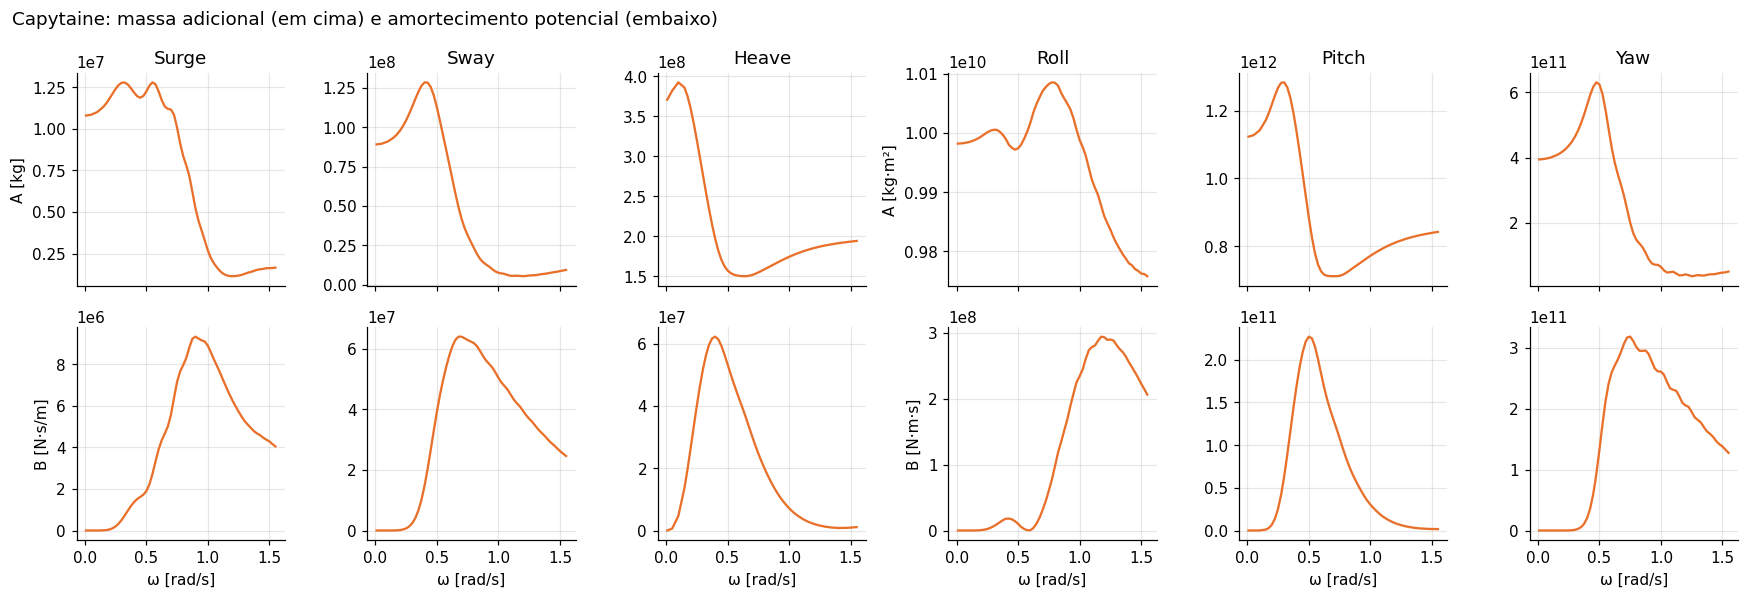

In [9]:
def diag(da, dof):
    return da.sel(radiating_dof=dof, influenced_dof=dof)

fig, axs = plt.subplots(2, 6, figsize=(16, 5.5), sharex=True)
for k, dof in enumerate(DOFS):
    u = 'kg·m²' if dof in ROT else 'kg'
    axs[0, k].plot(ds.omega, diag(ds.added_mass, dof), color=COR['Capytaine'])
    axs[0, k].set_title(dof)
    axs[0, k].set_ylabel(f'A [{u}]' if k in (0, 3) else '')
    axs[1, k].plot(ds.omega, diag(ds.radiation_damping, dof), color=COR['Capytaine'])
    axs[1, k].set_ylabel(('B [' + ('N·m·s' if dof in ROT else 'N·s/m') + ']') if k in (0, 3) else '')
    axs[1, k].set_xlabel('ω [rad/s]')
fig.suptitle('Capytaine: massa adicional (em cima) e amortecimento potencial (embaixo)', x=0.01, ha='left')
fig.tight_layout(); plt.show()

## 6. RAOs nos 6 graus de liberdade (só amortecimento potencial)

Para cada frequência e direção, o RAO vem do sistema linear 6 × 6

$$\left[-\omega^2\big(\mathbf{M}+\mathbf{A}(\omega)\big) - i\omega\big(\mathbf{B}(\omega)+\mathbf{B}_{ext}\big) + \mathbf{C} + \mathbf{C}_{ext}\right]\boldsymbol{\xi}(\omega,\beta) = \mathbf{F}(\omega,\beta)$$

e `cpt.post_pro.rao` resolve esse sistema usando `inertia_matrix` e `hydrostatic_stiffness` do dataset. Nesta seção **B_ext = 0**: só há o amortecimento potencial calculado pelo BEM.

Unidades: m/m nas translações e rad/m nas rotações (nos gráficos convertemos para °/m).

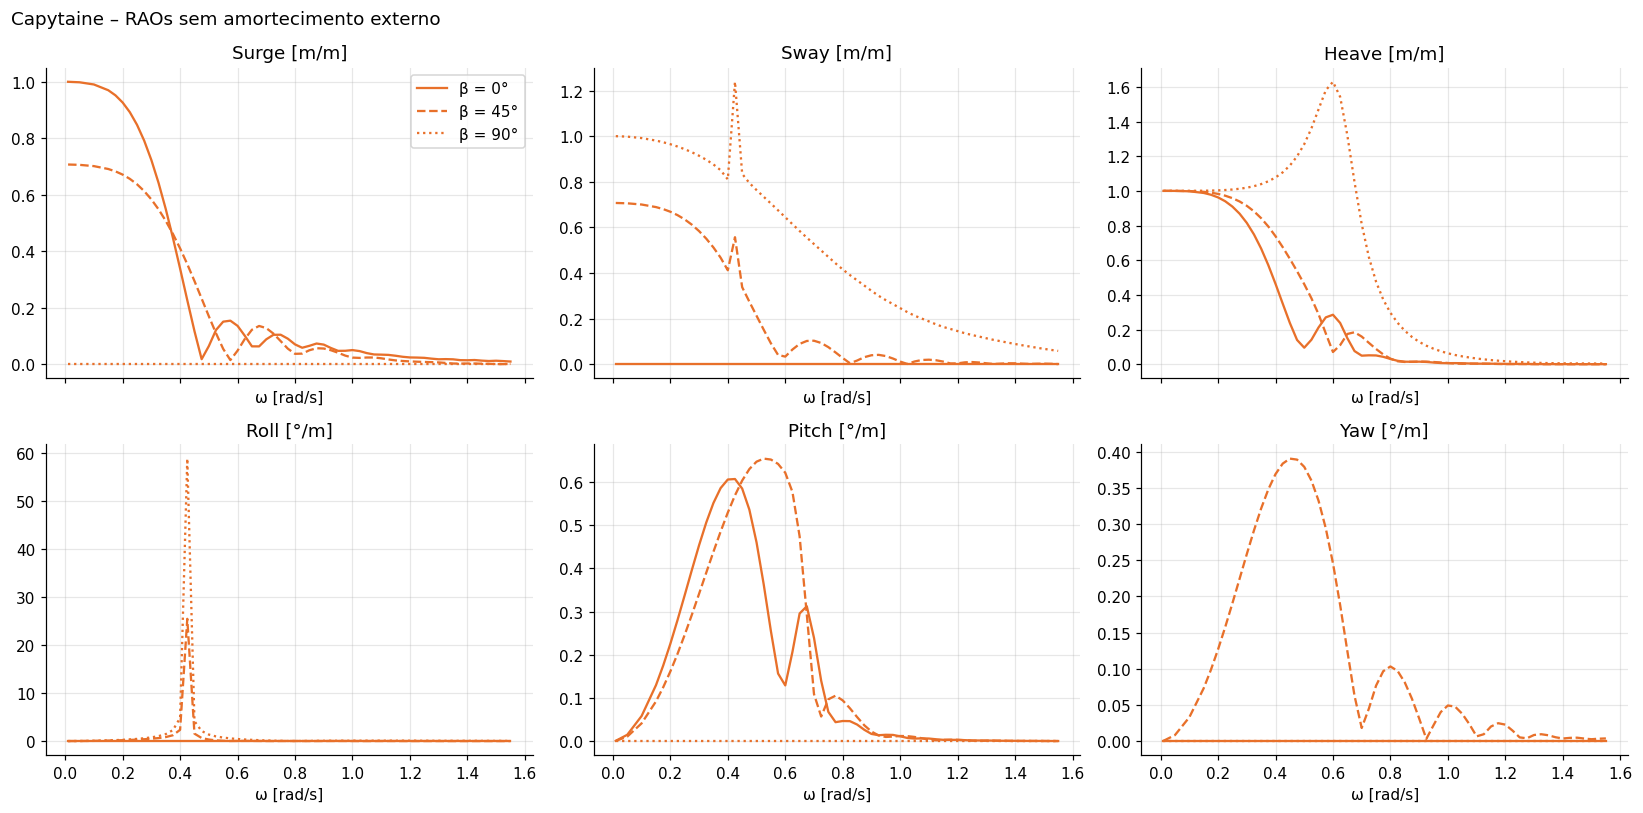

In [10]:
def em_unidades(dof, x):
    # rad/m -> °/m nas rotações
    return np.degrees(x) if dof in ROT else x

def rotulo(dof):
    return f'{dof} [°/m]' if dof in ROT else f'{dof} [m/m]'

rao_pot = cpt.post_pro.rao(ds)        # dims: omega × wave_direction × radiating_dof
fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
for ax, dof in zip(axs.flat, DOFS):
    for b, ls in zip([0, 45, 90], ['-', '--', ':']):
        r = rao_pot.sel(wave_direction=np.radians(b), method='nearest').sel(radiating_dof=dof)
        ax.plot(ds.omega, em_unidades(dof, np.abs(r)), ls, color=COR['Capytaine'], label=f'β = {b}°')
    ax.set_title(rotulo(dof)); ax.set_xlabel('ω [rad/s]')
axs[0, 0].legend()
fig.suptitle('Capytaine – RAOs sem amortecimento externo', x=0.01, ha='left')
fig.tight_layout(); plt.show()

**Frequências naturais.** Heave, roll e pitch têm restauração hidrostática; a frequência natural é a raiz de C_ii − ω²(M_ii + A_ii(ω)) = 0. Surge, sway e yaw não têm rigidez (o FPSO está livre, sem ancoragem) e, portanto, não têm frequência natural.

In [11]:
def freq_natural(ds, dof, M=None, C=None):
    w = ds.omega.values
    A = diag(ds.added_mass, dof).values
    M = ds.inertia_matrix.sel(influenced_dof=dof, radiating_dof=dof).item() if M is None else M
    C = ds.hydrostatic_stiffness.sel(influenced_dof=dof, radiating_dof=dof).item() if C is None else C
    f = C - w**2 * (M + A)
    i = np.where(np.diff(np.sign(f)) != 0)[0][0]
    wn = w[i] - f[i] * (w[i+1] - w[i]) / (f[i+1] - f[i])
    return wn, np.interp(wn, w, A), np.interp(wn, w, diag(ds.radiation_damping, dof).values)

linhas = []
for dof in ['Heave', 'Roll', 'Pitch']:
    wn, An, Bn = freq_natural(ds, dof)
    Mii = ds.inertia_matrix.sel(influenced_dof=dof, radiating_dof=dof).item()
    Cii = ds.hydrostatic_stiffness.sel(influenced_dof=dof, radiating_dof=dof).item()
    zeta = Bn / (2 * np.sqrt(Cii * (Mii + An)))
    linhas.append([dof, wn, 2 * np.pi / wn, An / Mii, 100 * zeta])
naturais = pd.DataFrame(linhas, columns=['GL', 'ωn [rad/s]', 'Tn [s]', 'A/M em ωn', 'ζ potencial [%]']).set_index('GL')
naturais.style.format('{:.3f}')

,ωn [rad/s],Tn [s],A/M em ωn,ζ potencial [%]
GL,,,,
Heave,0.606,10.364,1.223,12.390
Roll,0.423,14.859,0.414,0.063
Pitch,0.658,9.553,1.483,9.527


Note o **amortecimento potencial de roll**: menos de 0,1% do crítico. Sem outra fonte de amortecimento, o RAO de roll em mar de través fica enorme perto de Tn.

## 7. Inserindo um amortecimento externo no roll

O amortecimento externo é uma matriz 6 × 6, **B_ext**, somada a B(ω) na equação de movimento. Para o roll, é comum especificá-lo como uma fração ζ do amortecimento crítico:

$$B_{44}^{ext} = \zeta \, B_{44}^{crit} = 2\,\zeta\,\sqrt{C_{44}\,\big(I_{44}+A_{44}(\omega_{n})\big)}$$

**Passo a passo**

1. calcular ωn e A₄₄(ωn) (já feito na seção 6);
2. calcular B₄₄ para o ζ desejado;
3. montar a matriz B_ext com B₄₄ na posição (Roll, Roll) e zeros no resto;
4. passar a matriz em `cpt.post_pro.rao(ds, dissipation=B_ext)`.

In [12]:
def amortecimento_roll(ds, zeta):
    # B44 externo [N·m·s/rad] para uma fração zeta do amortecimento crítico de roll
    wn, A44, _ = freq_natural(ds, 'Roll')
    I44 = ds.inertia_matrix.sel(influenced_dof='Roll', radiating_dof='Roll').item()
    C44 = ds.hydrostatic_stiffness.sel(influenced_dof='Roll', radiating_dof='Roll').item()
    return 2 * zeta * np.sqrt(C44 * (I44 + A44))

def matriz_amortecimento(corpo, **termos):
    # matriz 6x6 rotulada, ex.: matriz_amortecimento(corpo, Roll=1e9)
    B = np.zeros((6, 6))
    for dof, valor in termos.items():
        i = DOFS.index(dof)
        B[i, i] = valor
    return corpo.add_dofs_labels_to_matrix(B)

B44_5 = amortecimento_roll(ds, 0.05)
print(f'B44 para 5% do crítico (Capytaine): {B44_5:.4e} N·m·s/rad')
print(f'B44 usado no WAMIT (ship.frc)     : {frc["amortecimento"][3, 3]:.4e} N·m·s/rad')

B_ext = matriz_amortecimento(corpo, Roll=B44_5)
B_ext

B44 para 5% do crítico (Capytaine): 1.4416e+09 N·m·s/rad
B44 usado no WAMIT (ship.frc)     : 1.4367e+09 N·m·s/rad


<xarray.DataArray (influenced_dof: 6, radiating_dof: 6)> Size: 288B
array([[0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 1.44162999e+09,
        0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00],
       [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, 0.00000000e+00,
        0.00000000e+00, 0.00000000e+00]])
Coordinates:
  * influenced_dof  (influenced_dof) <U5 120B 'Surge' 'Sway' ... 'Pitch' 'Yaw'
  * radiating_dof   (radiating_dof) <U5 120B 'Surge' 'Sway' ... 'Pitch' 'Yaw'

Os dois valores de B₄₄ ficam próximos: o B₄₄ do `ship.frc` também corresponde a cerca de 5% do crítico. Agora o efeito no RAO de roll em **mar de través (β = 90°)** para quatro níveis de amortecimento externo:

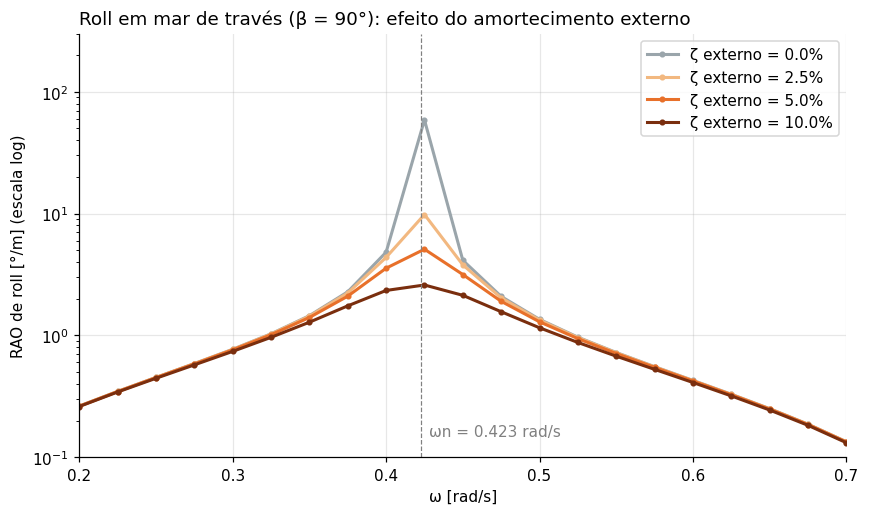

,ζ externo [%],pico do RAO [°/m],ω do pico [rad/s]
0,0.000,58.764,0.425
1,2.500,9.830,0.425
2,5.000,5.100,0.425
3,10.000,2.593,0.425


In [13]:
beta_roll = np.radians(90)
fig, ax = plt.subplots(figsize=(9, 5))
resumo = []
for zeta, cor in zip([0.0, 0.025, 0.05, 0.10], ['#9AA5AB', '#F2B880', '#E8702A', '#7A2E0E']):
    B = matriz_amortecimento(corpo, Roll=amortecimento_roll(ds, zeta))
    r = cpt.post_pro.rao(ds, dissipation=B).sel(wave_direction=beta_roll, method='nearest').sel(radiating_dof='Roll')
    r_deg = np.degrees(np.abs(r.values))
    ax.semilogy(ds.omega, r_deg, 'o-', ms=3, lw=2, color=cor, label=f'ζ externo = {100*zeta:.1f}%')
    resumo.append([100 * zeta, r_deg.max(), ds.omega.values[r_deg.argmax()]])
wn_roll = naturais.loc['Roll', 'ωn [rad/s]']
ax.axvline(wn_roll, color='gray', lw=0.8, ls='--')
ax.text(wn_roll + 0.005, 0.15, f'ωn = {wn_roll:.3f} rad/s', color='gray')
ax.set_xlabel('ω [rad/s]'); ax.set_ylabel('RAO de roll [°/m] (escala log)')
ax.set_title('Roll em mar de través (β = 90°): efeito do amortecimento externo', loc='left')
ax.set_xlim(0.2, 0.7); ax.set_ylim(0.1, 300); ax.legend(); plt.show()

pd.DataFrame(resumo, columns=['ζ externo [%]', 'pico do RAO [°/m]', 'ω do pico [rad/s]']).style.format('{:.3f}')

**Leitura.** O amortecimento externo quase não muda o RAO longe da ressonância, mas controla o pico: perto de ωn a resposta é limitada só pelo amortecimento. Com o amortecimento potencial sozinho, o RAO de roll em mar de través chega a quase 60 °/m, valor fisicamente irreal; com 5% do crítico ele cai para cerca de 5 °/m. (O eixo vertical está em escala logarítmica. Como as frequências estão espaçadas de 0,025 rad/s, o pico sem amortecimento externo é só indicativo: ele depende de quão perto de ωn cai a frequência calculada.)

**Outras formas de usar `dissipation`**
- Amortecimento em vários graus de liberdade ao mesmo tempo: `matriz_amortecimento(corpo, Roll=B44, Pitch=B55)`.
- Rigidez externa (por exemplo, a de um sistema de ancoragem): argumento `stiffness` de `cpt.post_pro.rao`, também como matriz 6 × 6 rotulada.

## 8. Comparação com o WAMIT nos seis graus de liberdade

O `force.4` do WAMIT já inclui o amortecimento externo do `ship.frc` (roll e pitch). Para comparar nas mesmas condições, aplicamos **exatamente a mesma matriz B_ext** no Capytaine.

In [24]:
rao_wam = wio.ler_rao(PASTA_WAMIT)                   # m/m e rad/m, complexo
coef_wam = wio.ler_force1(PASTA_WAMIT, rho=RHO)       # A(ω), B(ω) em SI

B_ext_wamit = corpo.add_dofs_labels_to_matrix(frc['amortecimento'])
rao_cap = cpt.post_pro.rao(ds, dissipation=B_ext_wamit)
print('Amortecimento externo aplicado (diagonal):', np.diag(frc['amortecimento']))

Amortecimento externo aplicado (diagonal): [0.00000e+00 0.00000e+00 0.00000e+00 1.43669e+09 6.60403e+10 0.00000e+00]


### 8.1 Massa adicional e amortecimento

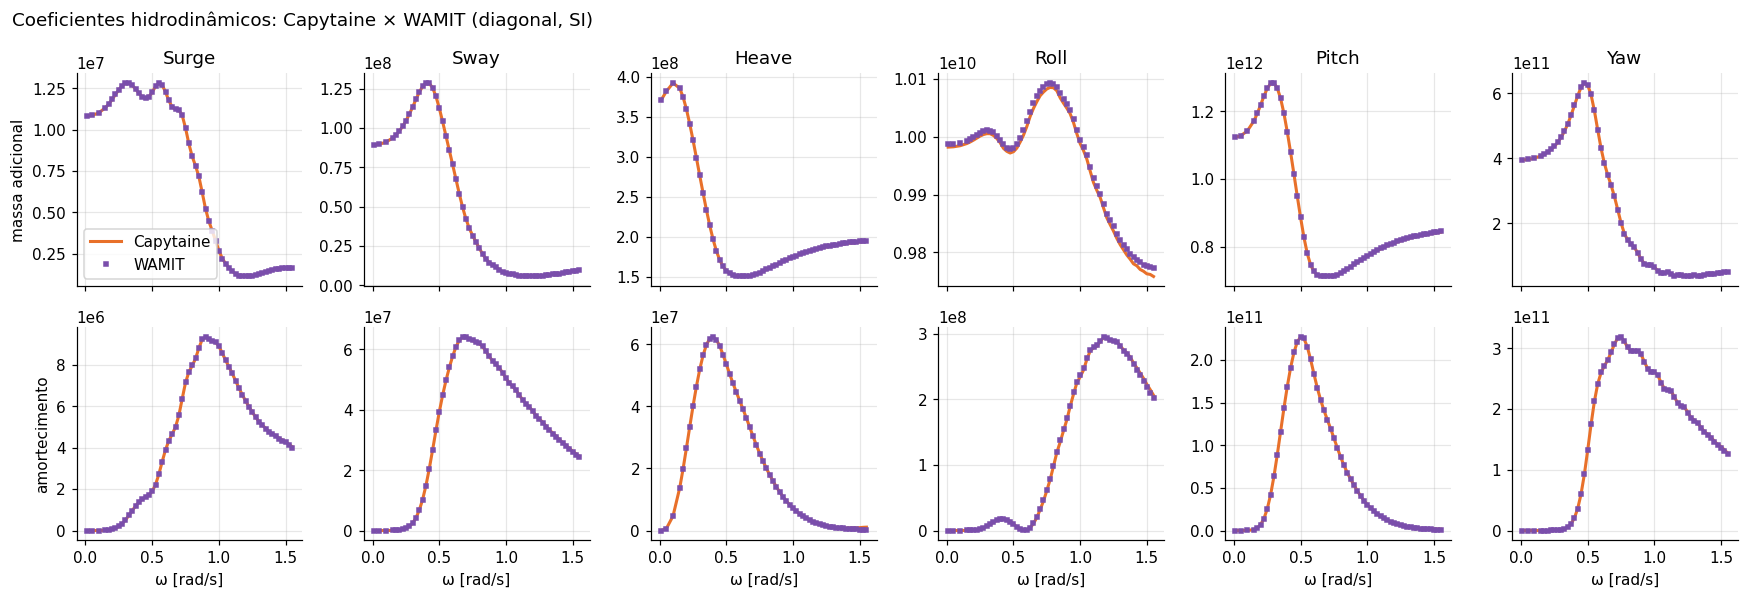

In [15]:
fig, axs = plt.subplots(2, 6, figsize=(16, 5.5), sharex=True)
for k, dof in enumerate(DOFS):
    for lin, var in enumerate(['added_mass', 'radiation_damping']):
        ax = axs[lin, k]
        ax.plot(ds.omega, diag(ds[var], dof), color=COR['Capytaine'], lw=2, label='Capytaine')
        ax.plot(coef_wam.omega, diag(coef_wam[var], dof), 's', ms=3, color=COR['WAMIT'], label='WAMIT')
        if lin == 0: ax.set_title(dof)
        else: ax.set_xlabel('ω [rad/s]')
axs[0, 0].set_ylabel('massa adicional'); axs[1, 0].set_ylabel('amortecimento')
axs[0, 0].legend()
fig.suptitle('Coeficientes hidrodinâmicos: Capytaine × WAMIT (diagonal, SI)', x=0.01, ha='left')
fig.tight_layout(); plt.show()

### 8.2 Por que `method='direct'`?

O roll é o grau de liberdade mais sensível à formulação. A célula abaixo recalcula só sway e roll em quatro frequências com as duas formulações do Capytaine, na mesma malha, e compara a massa adicional de roll com a do WAMIT (cerca de 20 s).

In [16]:
corpo_teste = cpt.FloatingBody(mesh=casco, lid_mesh=tampa, center_of_mass=CG,
                               dofs=cpt.rigid_body_dofs(only=['Sway', 'Roll'], rotation_center=CG))
w_teste = coef_wam.omega.values[[8, 16, 24, 32]]
mt = xr.Dataset(coords={'omega': w_teste, 'radiating_dof': ['Sway', 'Roll'],
                        'water_depth': [np.inf], 'rho': RHO, 'g': G})
linhas = {'ω [rad/s]': w_teste,
          'WAMIT': diag(coef_wam.added_mass, 'Roll').sel(omega=w_teste).values}
for metodo in ['indirect', 'direct']:
    d = cpt.BEMSolver(method=metodo).fill_dataset(mt, corpo_teste, progress_bar=False)
    linhas[f"Capytaine '{metodo}'"] = diag(d.added_mass, 'Roll').values
tab = pd.DataFrame(linhas).set_index('ω [rad/s]')
for metodo in ['indirect', 'direct']:
    tab[f"dif. '{metodo}' [%]"] = 100 * (tab[f"Capytaine '{metodo}'"] / tab['WAMIT'] - 1)
tab.style.format('{:.4g}').format({c: '{:+.1f}' for c in tab.columns if 'dif' in c})

,WAMIT,Capytaine 'indirect',Capytaine 'direct',dif. 'indirect' [%],dif. 'direct' [%]
ω [rad/s],,,,,
0.275001,10009254150.000000,9592136323.741749,10003787736.770794,-4.2,-0.1
0.474999,9978102350.000000,9544687975.426357,9971812532.833817,-4.3,-0.1
0.675000,10069977200.000000,9612838071.104046,10060673368.932045,-4.5,-0.1
0.875000,10065267325.000000,9637354253.740299,10058051367.007877,-4.3,-0.1


Com a formulação indireta, a massa adicional de roll fica cerca de 4% abaixo da do WAMIT; com a direta, a diferença cai para menos de 0,5%. Em heave a diferença entre as formulações é de cerca de 1%. Para reproduzir uma rodada do WAMIT, use a mesma formulação que ela usou.

### 8.3 RAOs em três direções de onda

Mar de proa (β = 0°), mar de bochecha (β = 45°) e mar de través (β = 90°). Por simetria do casco, β = 180° repete β = 0° e β = 135° repete β = 45°.

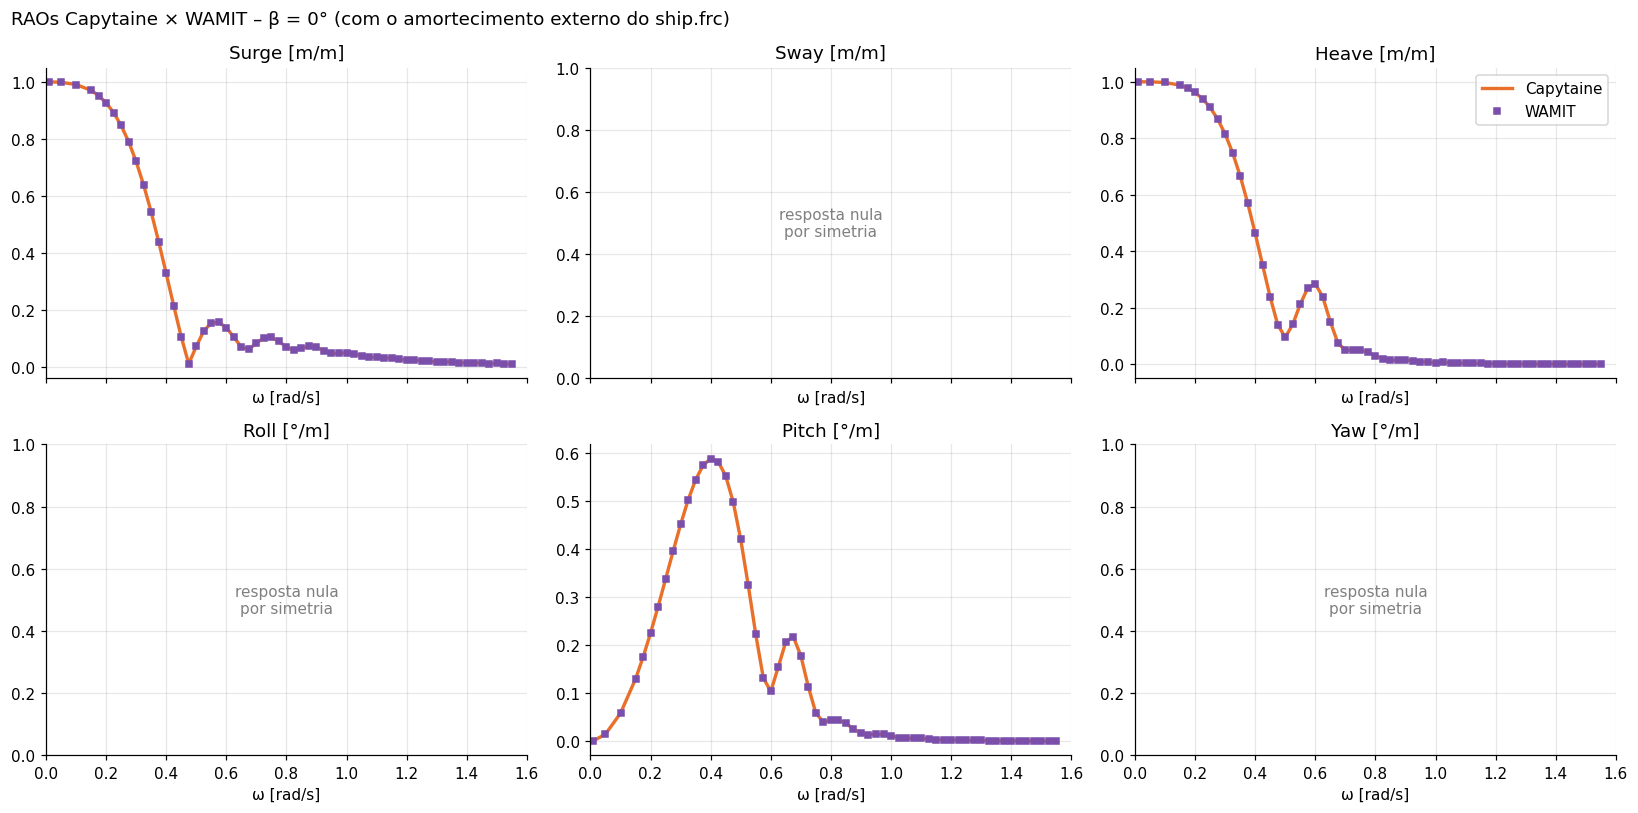

In [25]:
def compara_rao(beta_graus):
    b = np.radians(beta_graus)
    fig, axs = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
    for ax, dof in zip(axs.flat, DOFS):
        rc = np.abs(rao_cap.sel(wave_direction=b, method='nearest').sel(radiating_dof=dof).values)
        rw = np.abs(rao_wam.sel(wave_direction=b, method='nearest').sel(influenced_dof=dof).values)
        ax.set_title(rotulo(dof)); ax.set_xlabel('ω [rad/s]'); ax.set_xlim(0, 1.6)
        if max(em_unidades(dof, rc).max(), em_unidades(dof, rw).max()) < 1e-3:
            # resposta nula por simetria: só ruído numérico (< 0,001)
            ax.set_ylim(0, 1); ax.text(0.8, 0.5, 'resposta nula\npor simetria', ha='center', va='center', color='gray')
            continue
        ax.plot(ds.omega, em_unidades(dof, rc), color=COR['Capytaine'], lw=2.2, label='Capytaine')
        ax.plot(rao_wam.omega, em_unidades(dof, rw), 's', ms=3.5, color=COR['WAMIT'], label='WAMIT')
    axs[0, 2].legend()
    fig.suptitle(f'RAOs Capytaine × WAMIT – β = {beta_graus}° (com o amortecimento externo do ship.frc)',
                 x=0.01, ha='left')
    fig.tight_layout(); plt.show()

compara_rao(0)

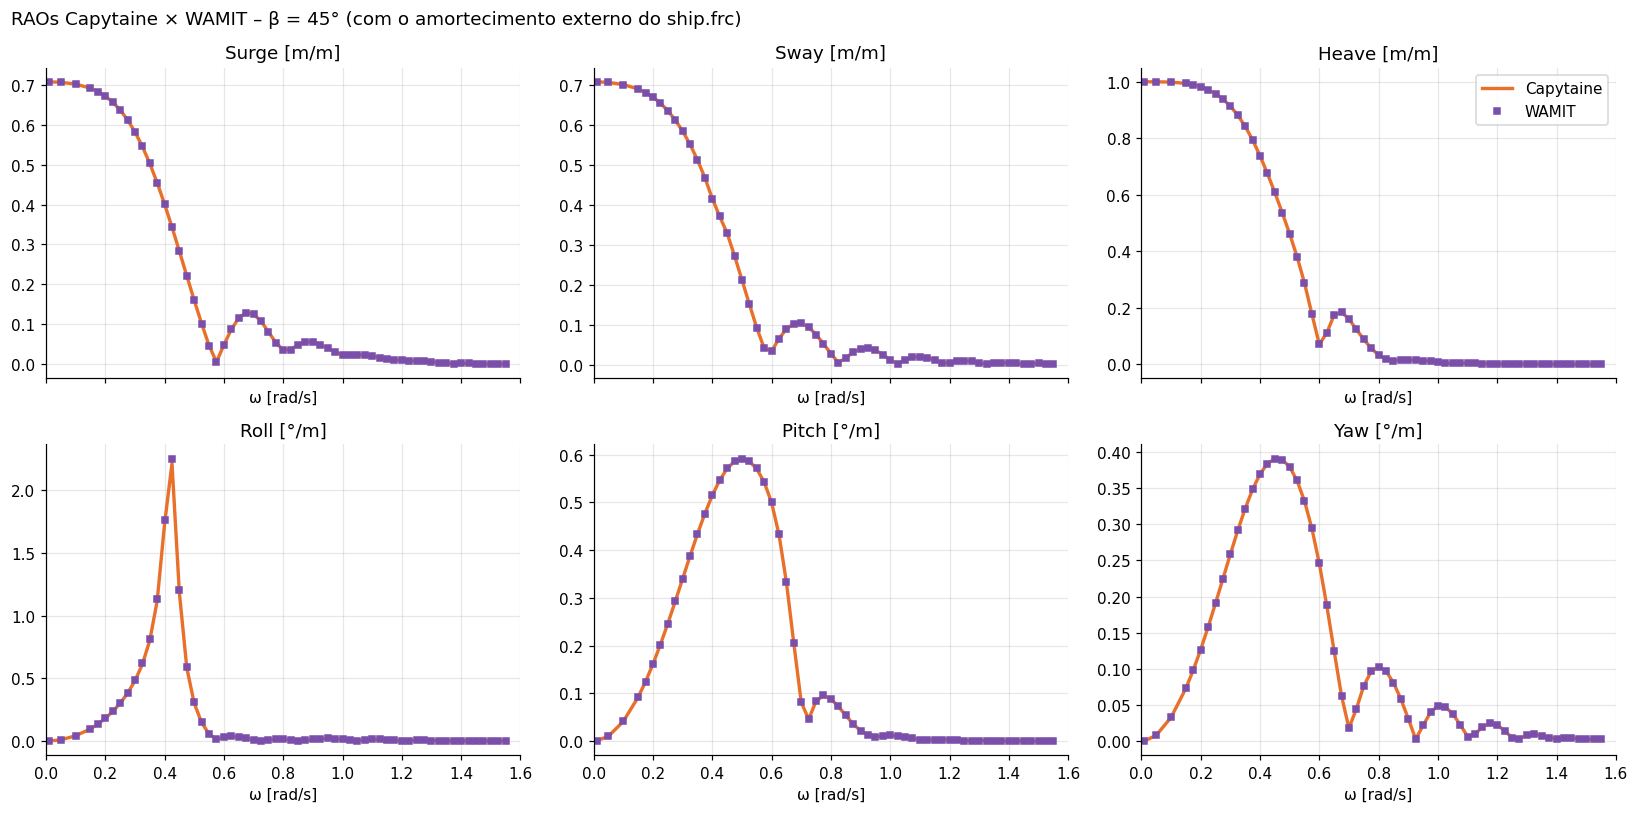

In [26]:
compara_rao(45)

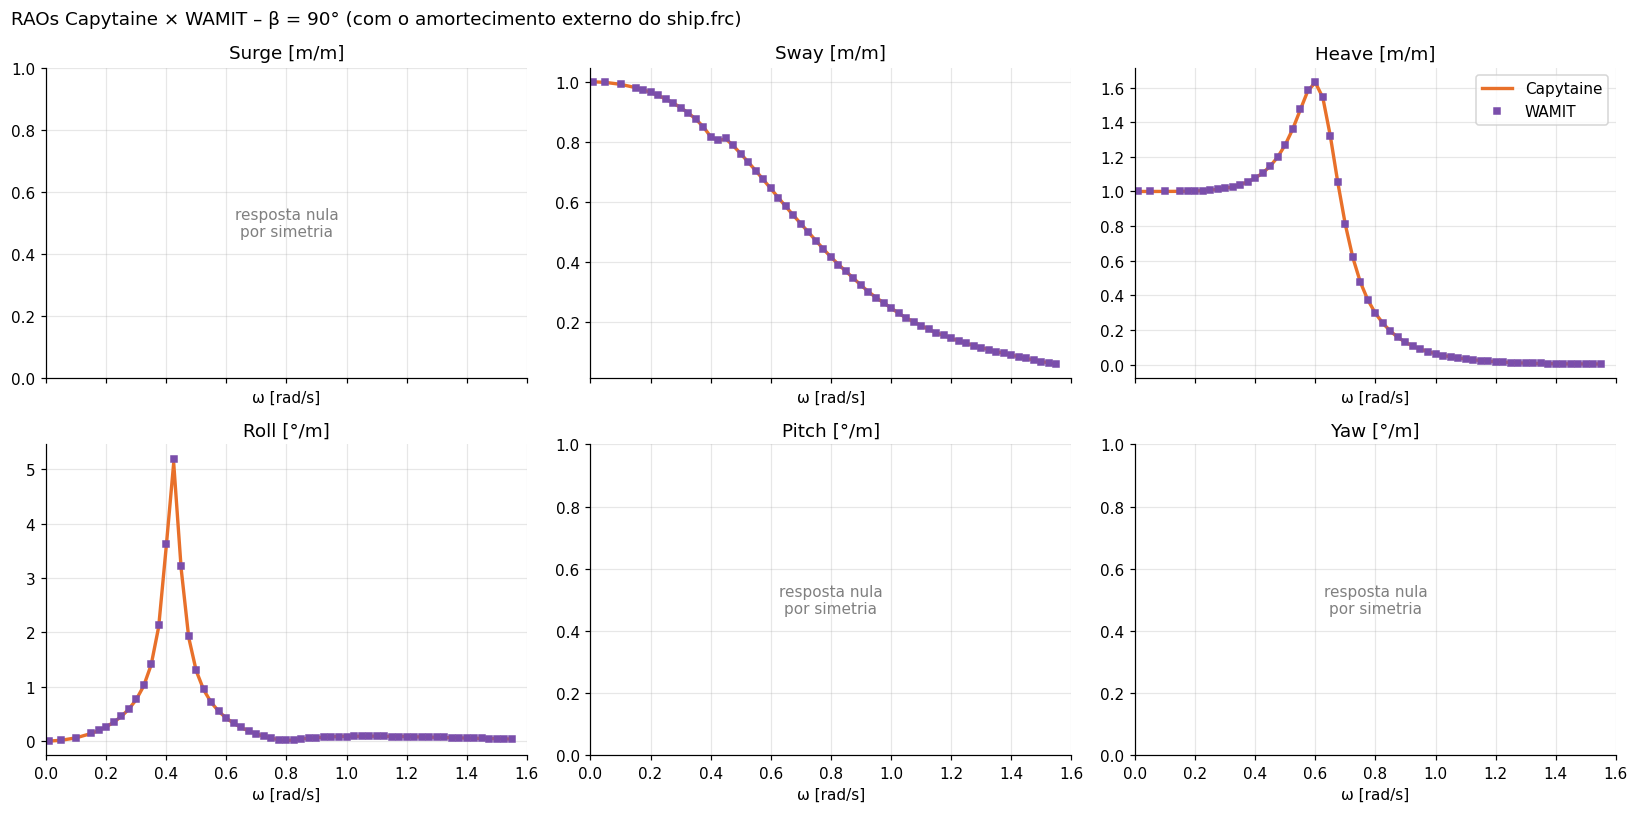

In [27]:
compara_rao(90)

### 8.4 Resumo numérico

Para cada direção e grau de liberdade com resposta não nula, a tabela mostra o valor máximo do RAO em cada programa e a **maior diferença ponto a ponto** entre as curvas, em porcentagem desse máximo. As frequências são as mesmas nos dois programas, então a comparação é direta.

In [29]:
linhas = []
for bg in [0, 45, 90]:
    b = np.radians(bg)
    for dof in DOFS:
        rc = em_unidades(dof, np.abs(rao_cap.sel(wave_direction=b, method='nearest').sel(radiating_dof=dof).values))
        rw = em_unidades(dof, np.abs(rao_wam.sel(wave_direction=b, method='nearest').sel(influenced_dof=dof).values))
        if rw.max() < 1e-3:
            continue                                   # resposta nula por simetria
        dif = 100 * np.max(np.abs(rc - rw)) / rw.max()
        linhas.append([bg, rotulo(dof), rc.max(), rw.max(), dif])
resumo = pd.DataFrame(linhas, columns=['β [°]', 'GL', 'máx. Capytaine', 'máx. WAMIT', 'maior diferença [% do máx.]'])
resumo.style.format({'máx. Capytaine': '{:.3f}', 'máx. WAMIT': '{:.3f}', 'maior diferença [% do máx.]': '{:.1f}'}).hide(axis='index')

β [°],GL,máx. Capytaine,máx. WAMIT,maior diferença [% do máx.]
0,Surge [m/m],1.000,1.000,0.0
0,Heave [m/m],1.000,1.000,0.1
0,Pitch [°/m],0.589,0.589,0.1
45,Surge [m/m],0.707,0.707,0.1
45,Sway [m/m],0.707,0.707,0.1
45,Heave [m/m],1.000,1.000,0.1
45,Roll [°/m],2.215,2.254,1.7
45,Pitch [°/m],0.591,0.591,0.2
45,Yaw [°/m],0.390,0.390,0.1
90,Sway [m/m],1.000,1.000,0.1


In [30]:
# frequências naturais com os coeficientes de cada programa
ds_w = coef_wam.assign(inertia_matrix=ds.inertia_matrix, hydrostatic_stiffness=ds.hydrostatic_stiffness)
tab = []
for dof in ['Heave', 'Roll', 'Pitch']:
    wc, _, _ = freq_natural(ds, dof)
    ww, _, _ = freq_natural(ds_w, dof)
    tab.append([dof, 2 * np.pi / wc, 2 * np.pi / ww, 100 * (ww / wc - 1)])
pd.DataFrame(tab, columns=['GL', 'Tn Capytaine [s]', 'Tn WAMIT [s]', 'diferença em ωn [%]']).set_index('GL').style.format('{:.2f}')

,Tn Capytaine [s],Tn WAMIT [s],diferença em ωn [%]
GL,,,
Heave,10.36,10.37,-0.03
Roll,14.86,14.86,-0.01
Pitch,9.55,9.56,-0.03


## 9. Resumo e exercícios propostos

**Resumo**
- Com a mesma malha, as mesmas frequências e direções, a mesma formulação (`method='direct'`), a mesma massa e o mesmo amortecimento externo, o Capytaine reproduz o WAMIT nos seis graus de liberdade: os períodos naturais coincidem em 0,1% e a maior diferença entre RAOs é inferior a 2% do valor máximo (roll).
- O roll é o grau de liberdade mais sensível: o amortecimento potencial é pequeno e o pico do RAO depende quase só do amortecimento externo, que precisa ser estimado à parte (ensaio de decaimento, métodos empíricos como o de Ikeda).
- Surge, sway e yaw não têm restauração; sem ancoragem, suas respostas crescem para ondas longas.

**Exercícios**
1. Repita a seção 7 com ζ = 10% e 15% e trace o pico do RAO de roll em função de ζ.
2. Gere uma malha própria com `cpt.mesh_parallelepiped` (como na Aula 09) e compare com a malha do WAMIT. Quantos painéis são necessários para os resultados mudarem menos de 1%?
3. Adicione uma rigidez de ancoragem em surge e sway com o argumento `stiffness` de `cpt.post_pro.rao` e observe o aparecimento de frequências naturais horizontais.